# Wine Quality Assessment Using Physicochemical Properties

## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Load the Dataset

In [2]:
df = pd.read_csv("winequality-red.csv", sep=";")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## Dataset Information

In [3]:
df.shape

(1599, 12)

In [4]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [6]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [7]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

## Data Preprocessing

In [8]:
df.duplicated().sum()

np.int64(240)

In [9]:
df.drop_duplicates(inplace=True)

In [10]:
df.duplicated().sum()

np.int64(0)

# Task 1 : Statistical Analysis

### a) Calculate Mean, Median, Mode, Standard Deviation and Skewness

In [11]:
cols = ["alcohol", "volatile acidity", "residual sugar"]

stats = pd.DataFrame({
    "Mean": df[cols].mean(),
    "Median": df[cols].median(),
    "Mode": df[cols].mode().iloc[0],
    "Std Dev": df[cols].std(),
    "Skewness": df[cols].skew()
})

stats

,Mean,Median,Mode,Std Dev,Skewness
alcohol,10.432315,10.20,9.5,1.082065,0.859841
volatile acidity,0.529478,0.52,0.5,0.183031,0.729279
residual sugar,2.523400,2.20,2.0,1.352314,4.548153


### Observation

The table shows the central tendency and distribution of alcohol, volatile acidity and residual sugar. Skewness indicates whether the data is symmetric or skewed.

### b) Relative Variability

In [12]:
cv = (df[cols].std() / df[cols].mean()) * 100

cv

alcohol             10.372246
volatile acidity    34.568286
residual sugar      53.590948
dtype: float64

In [13]:
cv.idxmax()

'residual sugar'

### Observation

The attribute with the highest coefficient of variation has the greatest relative variability.

### c) Pearson Correlation between Alcohol and Quality

In [14]:
corr = df["alcohol"].corr(df["quality"])

corr

np.float64(0.48034289800199187)

### Interpretation

The Pearson correlation coefficient indicates the direction and strength of the relationship between alcohol content and wine quality.

# Task 2: Exploratory Data Analysis (EDA)

## Task 2(a): Histogram of Wine Quality Scores

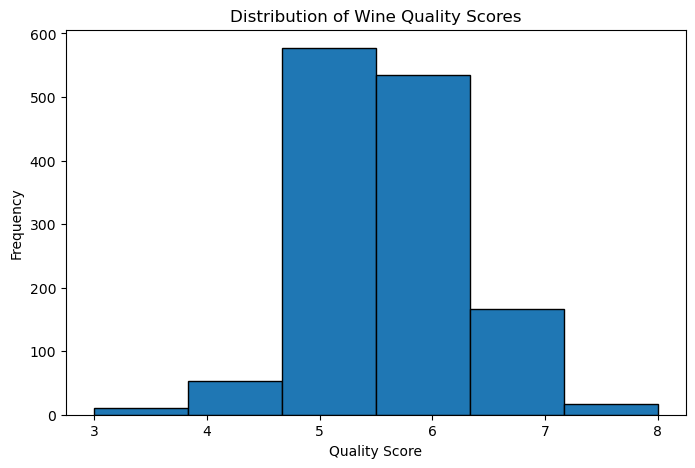

In [15]:
plt.figure(figsize=(8,5))

plt.hist(df["quality"], bins=6, edgecolor="black")

plt.title("Distribution of Wine Quality Scores")
plt.xlabel("Quality Score")
plt.ylabel("Frequency")

plt.show()

### Interpretation

The histogram shows how wine quality scores are distributed across the dataset. It helps identify the most common quality scores and whether the distribution is symmetric or skewed.

## Task 2(b): Box Plot of Alcohol Content by Wine Quality

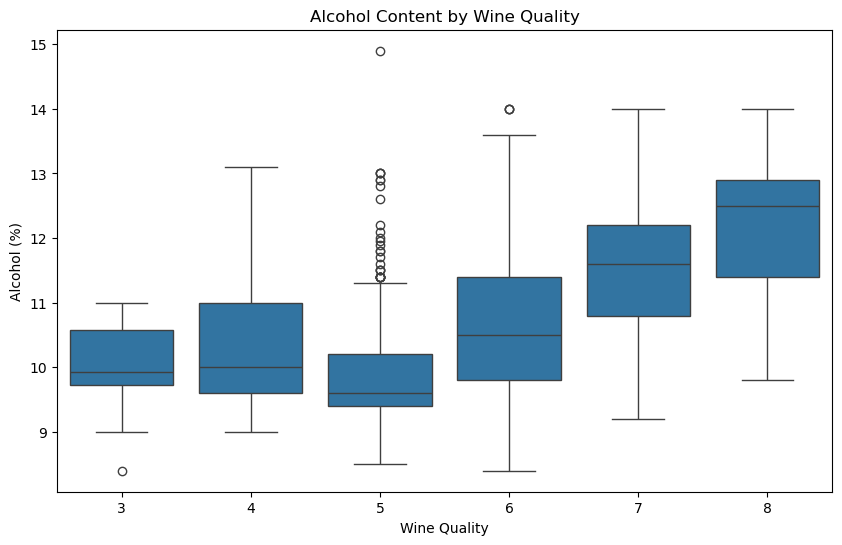

In [16]:
plt.figure(figsize=(10,6))

sns.boxplot(x="quality", y="alcohol", data=df)

plt.title("Alcohol Content by Wine Quality")
plt.xlabel("Wine Quality")
plt.ylabel("Alcohol (%)")

plt.show()

### Interpretation

The box plot compares alcohol content across different wine quality scores. It also helps identify outliers and differences in alcohol levels among quality groups.

## Task 2(c): Correlation Heatmap

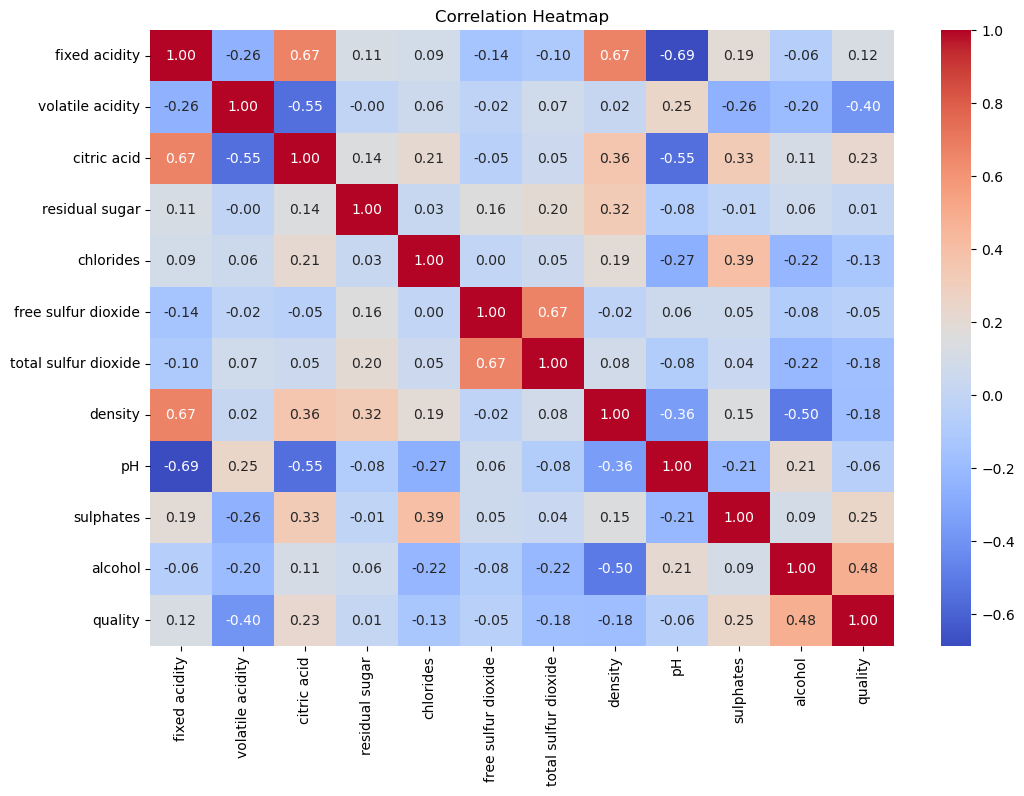

In [17]:
plt.figure(figsize=(12,8))

sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")

plt.show()

### Interpretation

The heatmap shows the correlation between all physicochemical attributes and wine quality. Positive values indicate direct relationships, while negative values indicate inverse relationships.

## Task 2(d): Attributes Most Strongly Associated with Quality

In [18]:
corr = df.corr()["quality"].drop("quality")

corr = corr.reindex(corr.abs().sort_values(ascending=False).index)

corr

alcohol                 0.480343
volatile acidity       -0.395214
sulphates               0.248835
citric acid             0.228057
density                -0.184252
total sulfur dioxide   -0.177855
chlorides              -0.130988
fixed acidity           0.119024
pH                     -0.055245
free sulfur dioxide    -0.050463
residual sugar          0.013640
Name: quality, dtype: float64

In [19]:
print(corr.head(2))

alcohol             0.480343
volatile acidity   -0.395214
Name: quality, dtype: float64


### Interpretation

The two attributes with the highest absolute Pearson correlation are considered the strongest predictors of wine quality. Their correlation values indicate whether their relationship with quality is positive or negative.

# Task 3: Predictive Modelling

## Task 3(a): Develop a Multiple Linear Regression Model

In [20]:
X = df.drop("quality", axis=1)
y = df["quality"]

## Task 3(b): Split the Dataset into Training and Testing Sets

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

## Standardize the Features

In [22]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Train the Linear Regression Model

In [23]:
model = LinearRegression()

model.fit(X_train_scaled, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


## Predict Wine Quality

In [24]:
y_pred = model.predict(X_test_scaled)

## Task 3(c): Model Evaluation

In [25]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 0.5041409053480713
MSE : 0.4310090050900972
RMSE: 0.656512760797608
R²  : 0.3915360499058189


## Task 3(d): Standardized Regression Coefficients

In [26]:
coef = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coef["Absolute"] = coef["Coefficient"].abs()

coef = coef.sort_values("Absolute", ascending=False)

coef

,Feature,Coefficient,Absolute
10,alcohol,0.333970,0.333970
1,volatile acidity,-0.178494,0.178494
9,sulphates,0.148499,0.148499
6,total sulfur dioxide,-0.123600,0.123600
8,pH,-0.121548,0.121548
4,chlorides,-0.115971,0.115971
0,fixed acidity,-0.049675,0.049675
5,free sulfur dioxide,0.048723,0.048723
7,density,0.042064,0.042064
2,citric acid,-0.019148,0.019148


In [27]:
coef.head(2)

,Feature,Coefficient,Absolute
10,alcohol,0.333970,0.333970
1,volatile acidity,-0.178494,0.178494


In [28]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [29]:
vif = pd.DataFrame()

vif["Feature"] = X.columns

vif["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

vif

,Feature,VIF
0,fixed acidity,75.023032
1,volatile acidity,16.460387
2,citric acid,9.188892
3,residual sugar,4.915733
4,chlorides,6.349793
5,free sulfur dioxide,6.432241
6,total sulfur dioxide,6.543918
7,density,1500.387873
8,pH,1095.732046
9,sulphates,21.946341


## Task 3(e): Actual vs Predicted Wine Quality

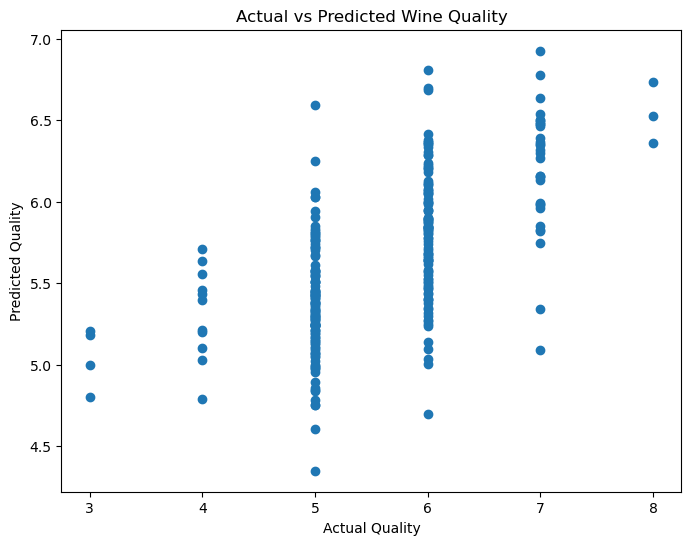

In [30]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.title("Actual vs Predicted Wine Quality")

plt.xlabel("Actual Quality")

plt.ylabel("Predicted Quality")

plt.show()

### Interpretation

The scatter plot compares the predicted wine quality scores with the actual quality scores. Points closer to an imaginary 45-degree line indicate better predictions. Any noticeable spread away from this line suggests prediction errors and highlights the limitations of the linear regression model.

# Task 4: Business Decision Making

## Task 4(a): Measurements Recommended for Quality Screening

In [31]:
print("Top Two Predictors:")
print(coef.head(2))

Top Two Predictors:
             Feature  Coefficient  Absolute
10           alcohol     0.333970  0.333970
1   volatile acidity    -0.178494  0.178494


### Recommendation

Based on the regression coefficients and correlation analysis, the two measurements that deserve the most attention during laboratory quality screening are the two attributes with the highest influence on wine quality.

These measurements show the strongest relationship with quality and therefore provide valuable information for predicting wine quality before sensory evaluation.

## Task 4(b): Can the Regression Model Replace Sensory Evaluation?

### Discussion

The regression model provides useful predictions of wine quality based on physicochemical properties. However, it should not completely replace sensory evaluation because taste, aroma and overall consumer perception cannot be fully captured using laboratory measurements alone.

The evaluation metrics (MAE, RMSE and R²) indicate that the model can support quality assessment but should be used as an assisting tool rather than a complete replacement for expert tasting.

## Task 4(c): Limitations

### Limitations

1. The dataset contains only physicochemical measurements and does not include sensory characteristics such as aroma, flavor or texture.

2. Linear Regression assumes a linear relationship between variables. Wine quality may depend on more complex non-linear interactions that are not captured by this model.

# Conclusion

This study analyzed the relationship between physicochemical properties and wine quality using statistical analysis, exploratory data analysis and multiple linear regression.

The statistical analysis identified important characteristics of the dataset, while the correlation analysis highlighted the attributes most strongly associated with wine quality.

The regression model demonstrated that physicochemical measurements can reasonably predict wine quality, although they cannot completely replace human sensory evaluation. Therefore, laboratory measurements should be used as a decision-support tool for preliminary quality screening, followed by expert tasting for final quality assessment.